A few select points:
  Time (min)   [A_approx] (M)    [A_exact] (M)
       0.000           1.0000           1.0000
       2.500           0.5000           0.6065
       5.000           0.2500           0.3679
       7.500           0.1250           0.2231
      10.000           0.0625           0.1353


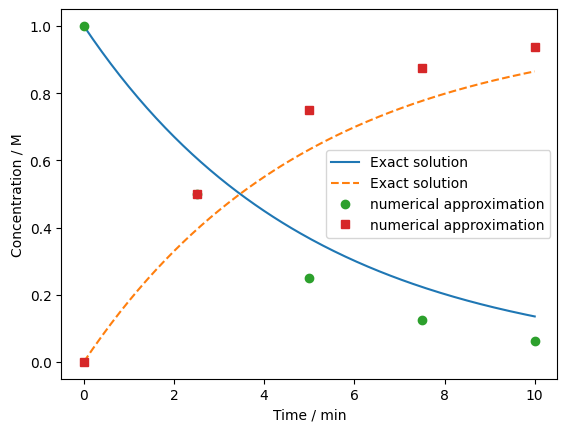

In [1]:
import math
import matplotlib.pyplot as plt


# Setup our model. Initial concentrations, rate constant, time step, and run time
# You can edit these to change the model.
A0 = 1.00         # initial [A], M
B0 = 0.00         # initial [B], M
k = 0.20          # first-order rate constant, min^-1
dt = 2.5         # time step, min
final_time = 10.00  # total reaction time, min

# This sets up a place to store our data
steps = round(final_time / dt)
A = A0
B = B0
time = [0.0]
A_values = [A]
B_values = [B]

# Here is where we do the numerical approximation
# We will calculate the change in concentration at each time step
for step in range(steps):
    rate = k * A
    change = rate * dt
    A = A - change
    B = B + change

    # This appends the data for each time step
    time.append((step + 1) * dt)
    A_values.append(A)
    B_values.append(B)

exact_A = [A0 * math.exp(-k * t) for t in time]

# print out 5 points of data
print("A few select points:")
print(f"{'Time (min)':>12} {'[A_approx] (M)':>16} {'[A_exact] (M)':>16}")

check_points = [0, steps // 4, steps // 2, 3 * steps // 4, steps]

for i in check_points:
    print(f"{time[i]:12.3f} {A_values[i]:16.4f} {exact_A[i]:16.4f}")

exact_time = [final_time * point / 200 for point in range(201)]
exact_A = [A0 * math.exp(-k * t) for t in exact_time]
exact_B = [B0 + A0 * (1 - math.exp(-k * t)) for t in exact_time]

## This code plots the results.  Don't worry about the details.
plt.plot(exact_time, exact_A, '-', label='Exact solution')
plt.plot(exact_time, exact_B, '--', label='Exact solution')
plt.plot(time, A_values, 'o', label='numerical approximation')
plt.plot(time, B_values, 's', label='numerical approximation')
plt.xlabel('Time / min')
plt.ylabel('Concentration / M')
plt.legend()
plt.show()

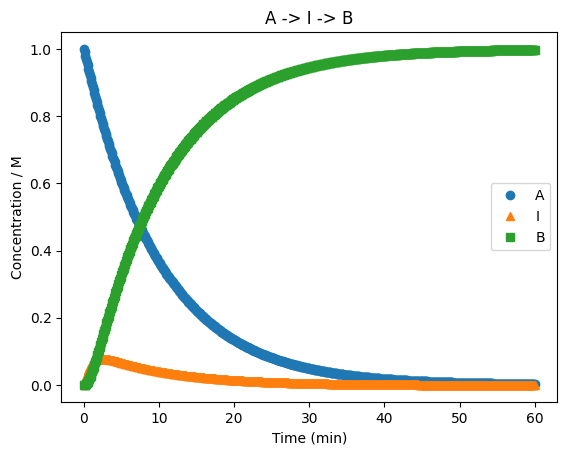

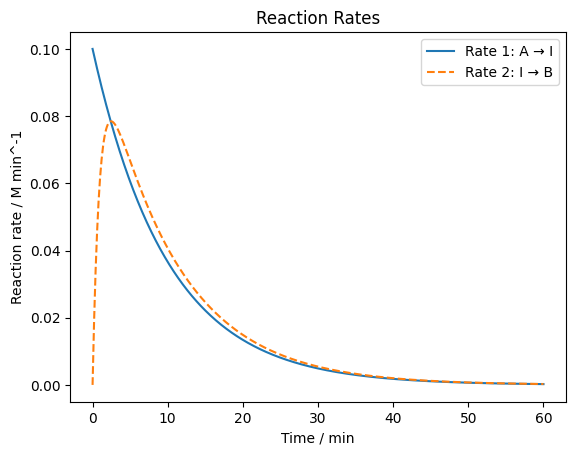

In [2]:
# Intermediate species in a 2 step reaction
# A -> I   rate 1 = k1[A]
# I -> B   rate 2 = k2[I]

A0 = 1.00          # M
I0 = 0.00          # M
B0 = 0.00          # M
k1 = 0.10          # A -> I rate constant, min^-1
k2 = 1.00          # I -> B rate constant, min^-1
dt = 0.10          # time step, min
final_time = 60.00 # min

# Starting values and storage.

# This sets up a place to store our data
steps = round(final_time / dt)


A = A0
I = I0
B = B0
time = [0.0]
A_values=[A]
I_values=[I]
B_values=[B]
rate1_values = []
rate2_values = []

# Numerical approximation to solution of differential equations
for step in range(steps):
    rate1 = k1 * A
    rate2 = k2 * I

    change1 = rate1 * dt
    change2 = rate2 * dt

    A = A - change1
    I = I + change1 - change2
    B = B + change2
    
    # Store the result
    time.append((step + 1) * dt)
    A_values.append(A)
    I_values.append(I)
    B_values.append(B)
    rate1_values.append(rate1)
    rate2_values.append(rate2)

rate1_values.append(k1 * A)
rate2_values.append(k2 * I)
# plot
import matplotlib.pyplot as plt

plt.plot(time, A_values, 'o', label='A')
plt.plot(time, I_values, '^', label='I')
plt.plot(time, B_values, 's', label='B')
plt.xlabel('Time (min)')
plt.ylabel('Concentration / M')
plt.title('A -> I -> B')
plt.legend()
plt.show()

plt.plot(time, rate1_values, '-', label='Rate 1: A → I')
plt.plot(time, rate2_values, '--', label='Rate 2: I → B')
plt.xlabel('Time / min')
plt.ylabel('Reaction rate / M min^-1')
plt.title('Reaction Rates')
plt.legend()
plt.show()

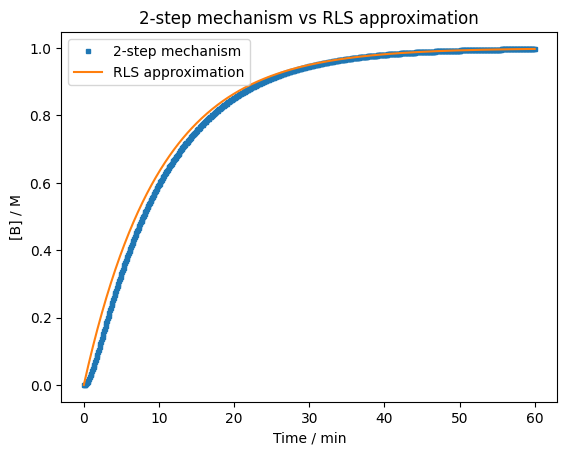

In [3]:
# This is the first order integrated rate law for step 1.
# If step 1 is the rate limiting step then it will do a good job approximating 
# the concentration of B
B_RLS = [A0 * (1 - math.exp(-k1 * t)) for t in time]

# Compare numerical results with RLS approximation
plt.plot(time, B_values, 's', markersize=3,
         label='2-step mechanism')
plt.plot(time, B_RLS, '-',
         label='RLS approximation')

plt.xlabel('Time / min')
plt.ylabel('[B] / M')
plt.title('2-step mechanism vs RLS approximation')
plt.legend()
plt.show()

In [4]:
# optional challenge:  model a reversible reaction!  A <--> B

# A -> B  rate1 = k1[A]
# B -> A  rate2 = k2[B]

A0 = 1.00          # M
B0 = 0.00          # M
k1 = 0.10          # A -> B rate constant, min^-1
k2 = 1.00          # B -> A rate constant, min^-1
dt = 0.10          # time step, min
final_time = 60.00 # min

# Starting values and storage.
steps = round(final_time / dt)
A = A0
B = B0
time = [0.0]
A_values=[A]
B_values=[B]
rate1_values = []
rate2_values = []

# Approximation to solving the differential equation
for step in range(steps):
    # fill in the next two lines
    rate1 = 
    rate2 = 

    change1 = rate1 * dt
    change2 = rate2 * dt

    # fill in the next two lines
    A = 
    B = 
    
    # Store the result
    time.append((step + 1) * dt)
    A_values.append(A)
    B_values.append(B)
    rate1_values.append(rate1)
    rate2_values.append(rate2)

rate1_values.append(k1 * A)
rate2_values.append(k2 * B)
# plot
import matplotlib.pyplot as plt

plt.plot(time, A_values, 'o', label='A')
plt.plot(time, B_values, 's', label='B')
plt.xlabel('Time (min)')
plt.ylabel('Concentration / M')
plt.title('A <--> B')
plt.legend()
plt.show()

# print final values
print(f"Final [A] = {A_values[-1]:.4f} M")
print(f"Final [B] = {B_values[-1]:.4f} M")
print(f"Ratio [B]/[A] = {B_values[-1]/A_values[-1]:.4f}")

SyntaxError: invalid syntax (2673013032.py, line 26)